# Metis sample traffic — exploratory data analysis

**Objective:** describe this sample, inspect request/session heterogeneity, and assess evidence for investigating caching, context optimization, and model/provider routing. This is not a production conclusion or routing implementation.

**Scope:** four equal category labels stay opaque; `input` is an uncertain configuration proxy; `instructions` is separate unverified metadata; naive timestamps are not API latency. Text stays in memory and saved evidence omits prompts and attachment URLs. Raw JSON is read-only.


## 1. Project and EDA objective

The investigation moves from data integrity to message/session behavior, language/request proxies, model/provider use, repetition, context, time, and business implications. Counts accompany percentages. This sample has only 100 sessions, so treat findings as descriptive and nonrepresentative until validated on the full dataset.


In [ ]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/sample_data/raw/data.json").exists():
    ROOT = ROOT.resolve().parents[1]
sys.path.insert(0, str(ROOT / "experiments/sample_eda"))
from eda_helpers import (
    add_text_features,
    analyze_request_heuristics,
    build_session_dataframe,
    context_features,
    data_dictionary,
    detect_language,
    duplicate_groups,
    flatten_messages,
    integrity_checks,
    load_sessions,
    most_common_value,
    normalize_exact,
    normalize_safe,
    numeric_summary,
    pair_bot_responses_with_preceding_users,
    percentile_90,
    safe_text_excerpt,
    schema_summary,
    summarize_missingness,
    summarize_values,
    near_duplicate_pairs,
)

In [2]:
DATA = ROOT / "data/sample_data/raw/data.json"
FIG = ROOT / "reports/sample_eda/figures"
TAB = ROOT / "reports/sample_eda/tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
raw_hash_before = hashlib.sha256(DATA.read_bytes()).hexdigest()
print("Raw SHA-256 before:", raw_hash_before)

Raw SHA-256 before: e0f56a2f2340b2ac70bf273e05ee2e9b56126cd3874c0c58659f46b4983549e1


## 2. Load data

The JSON root is a list of category objects containing session arrays. The category labels are retained as opaque strata only.


In [3]:
categories, session_items = load_sessions(DATA)
messages = add_text_features(flatten_messages(session_items))
sessions = build_session_dataframe(session_items, messages)
print(
    f"{len(categories)} category buckets | {len(sessions)} sessions | {len(messages)} messages"
)
display(summarize_values(messages, "role"))
display(
    pd.DataFrame(
        [(x["category"], len(x["sessions"])) for x in categories],
        columns=["opaque_category", "sessions"],
    )
)

4 category buckets | 100 sessions | 907 messages


,role,count,percent
0,user,465,51.267916
1,bot,442,48.732084


,opaque_category,sessions
0,developer_pegahdev,25
1,general_athena,25
2,operator_gapify,25
3,other_other,25


## 3. Raw schema and data dictionary

The field inventory distinguishes session and message grains. Role-dependent and optional fields are not automatically data errors; retrieval, attachment, input configuration, and instructions remain separate from ordinary message content.


In [4]:
schema = schema_summary(categories)
dictionary = data_dictionary(categories)
schema.to_csv(TAB / "schema_presence.csv", index=False)
dictionary.to_csv(TAB / "data_dictionary.csv", index=False)
display(schema)
display(dictionary)

,record_level,field,records_with_field,records,pct_present
0,category,category,4,4,100.000000
1,category,sessions,4,4,100.000000
2,session,bot_turns,100,100,100.000000
3,session,created_at,100,100,100.000000
4,session,messages,100,100,100.000000
5,session,session_id,100,100,100.000000
6,session,session_len,100,100,100.000000
7,session,user_turns,100,100,100.000000
8,message,attachments,14,907,1.543550
9,message,content,907,907,100.000000


,field,observed_type,grain,observed_presence_or_missingness,meaning_and_uncertainty
0,category,str,category bucket,4/4 have field; 0 null values,Opaque stratum; meaning intentionally undocume...
1,sessions,list,unverified,4/4 have field; 0 null values,Meaning not documented
2,bot_turns,int,session,100/100 have field; 0 null values,Declared bot-message count; checked against roles
3,created_at,str,session,100/100 have field; 0 null values,Naive timestamp; timezone semantics are unknown
4,messages,list,unverified,100/100 have field; 0 null values,Meaning not documented
5,session_id,str,session,100/100 have field; 0 null values,Session identifier; uniqueness is checked sepa...
6,session_len,int,session,100/100 have field; 0 null values,Declared message count; compared with parsed m...
7,user_turns,int,session,100/100 have field; 0 null values,Declared user-message count; checked against r...
8,attachments,list,message,14/907 have field; 0 null values,Attachment metadata; payloads/URLs excluded fr...
9,content,str,message,907/907 have field; 0 null values,Text payload; potentially sensitive and kept i...


## 4. Data quality and integrity

Checks compare declared counters to message roles, test duplicate session IDs, role vocabulary, timestamp parsing/order, and empty content. Equal timestamps are allowed; timestamps carry no timezone.


In [5]:
integrity = integrity_checks(categories, session_items, messages)
missingness = summarize_missingness(messages)
integrity.to_csv(TAB / "integrity_checks.csv", index=False)
missingness.to_csv(TAB / "message_missingness.csv", index=False)
display(integrity)
display(missingness.head(12))
print(
    "Message timestamp range:",
    messages.timestamp_dt.min(),
    "to",
    messages.timestamp_dt.max(),
)

,check,count,interpretation
0,duplicate session ID occurrences,0,Expect 0
1,declared session counter mismatches,0,Expect 0 across three counters per session
2,unexpected message roles,0,Expect 0 if role vocabulary is stable
3,unparseable message timestamps,0,Expect 0; naive timestamps remain timezone-amb...
4,within-session timestamp decreases,0,May indicate ordering or export issues; equal ...
5,empty message content,0,Inspect as structural edge cases


,column,dtype,null_count,null_pct
0,model,object,492,54.244763
1,provider,object,492,54.244763
2,instructions,object,492,54.244763
3,latin_char_proportion,float64,5,0.551268
4,persian_char_proportion,float64,5,0.551268
5,category,object,0,0.000000
6,has_fenced_code,bool,0,0.000000
7,sentence_count_approx,int64,0,0.000000
8,punctuation_count,int64,0,0.000000
9,digit_count,int64,0,0.000000


Message timestamp range: 2026-03-02 19:31:47 to 2026-09-09 15:56:39


## 5. Message-level text EDA

Metrics include characters, words, lines, punctuation, sentence proxy, script proportions, URLs, code-like text, Markdown-like formatting, and digits. Approximate tokens use ceil(characters/4); this is not model tokenization or billing, especially for Persian and code.


,metric,count,mean,median,std,min,p25,p50,p75,p90,p95,p99,max
0,char_count,907,312.23,86.0,878.34,2,26.0,86.0,239.0,704.4,1349.0,4154.40,13795
1,normalized_char_count,907,307.63,85.0,860.37,2,26.0,85.0,234.0,703.4,1330.9,4149.28,13783
2,word_count,907,56.09,17.0,134.12,0,5.0,17.0,46.0,134.0,227.7,564.16,1707
3,line_count,907,4.38,1.0,12.92,1,1.0,1.0,2.0,9.0,16.0,68.88,228
4,sentence_count_approx,907,4.62,1.0,10.27,1,1.0,1.0,5.0,10.0,17.0,34.88,208
5,punctuation_count,907,19.79,2.0,71.41,0,0.0,2.0,13.5,41.0,70.7,351.00,1214
6,digit_count,907,2.96,0.0,13.19,0,0.0,0.0,0.0,5.0,15.0,54.76,187
7,question_mark_count,907,0.46,0.0,0.98,0,0.0,0.0,1.0,1.0,2.0,5.00,10
8,approx_tokens_char_div4,907,78.43,22.0,219.60,1,7.0,22.0,60.0,176.4,337.6,1039.10,3449


,role,messages,median_chars,p90_chars,median_words
0,bot,442,210.0,1025.2,42.0
1,user,465,29.0,181.6,6.0


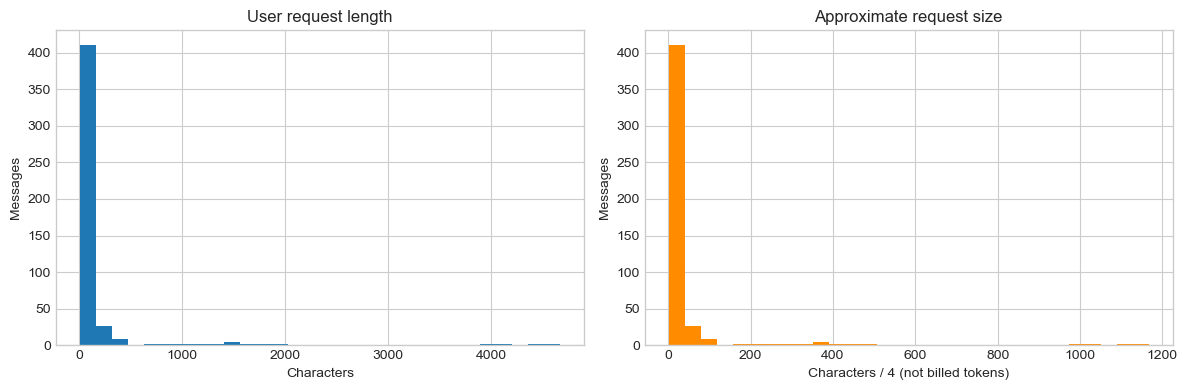

Text/format indicators by role (extremely long = ≥5,000 chars):


,role,feature,messages,percent_role
0,bot,has_url,14,3.167421
1,bot,has_code_like_text,27,6.108597
2,bot,has_fenced_code,7,1.583710
3,bot,has_markdown_like_formatting,92,20.814480
4,bot,is_empty,0,0.000000
5,bot,is_extremely_short,6,1.357466
6,bot,is_extremely_long,5,1.131222
7,user,has_url,7,1.505376
8,user,has_code_like_text,9,1.935484
9,user,has_fenced_code,0,0.000000


In [6]:
user = messages[messages.role.eq("user")].copy()
bot = messages[messages.role.eq("bot")].copy()
metrics = [
    "char_count",
    "normalized_char_count",
    "word_count",
    "line_count",
    "sentence_count_approx",
    "punctuation_count",
    "digit_count",
    "question_mark_count",
    "approx_tokens_char_div4",
]
text_stats = numeric_summary(messages, metrics)
text_stats.to_csv(TAB / "text_numeric_summary.csv", index=False)
role_stats = (
    messages.groupby("role")
    .agg(
        messages=("message_id", "count"),
        median_chars=("char_count", "median"),
        p90_chars=("char_count", percentile_90),
        median_words=("word_count", "median"),
    )
    .reset_index()
)
role_stats.to_csv(TAB / "message_length_by_role.csv", index=False)
display(text_stats.round(2))
display(role_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user.char_count, bins=30)
axes[0].set(title="User request length", xlabel="Characters", ylabel="Messages")
axes[1].hist(user.approx_tokens_char_div4, bins=30, color="darkorange")
axes[1].set(
    title="Approximate request size",
    xlabel="Characters / 4 (not billed tokens)",
    ylabel="Messages",
)
fig.tight_layout()
fig.savefig(FIG / "user_request_length.png", dpi=160, bbox_inches="tight")
plt.show()

text_flags = [
    "has_url",
    "has_code_like_text",
    "has_fenced_code",
    "has_markdown_like_formatting",
    "is_empty",
    "is_extremely_short",
    "is_extremely_long",
]
flag_rows = []
for role, group in messages.groupby("role"):
    for flag in text_flags:
        count = int(group[flag].sum())
        flag_rows.append(
            {
                "role": role,
                "feature": flag,
                "messages": count,
                "percent_role": 100 * count / len(group) if len(group) else 0,
            }
        )
text_flag_summary = pd.DataFrame(flag_rows)
text_flag_summary.to_csv(TAB / "text_indicators_by_role.csv", index=False)
print("Text/format indicators by role (extremely long = ≥5,000 chars):")
display(text_flag_summary)

**Interpretation.** Read the median and upper percentiles together with the histogram; a right tail may concentrate text volume in a few prompts. The token proxy is for rough relative sizing only.


## 6. Session and conversation EDA

We describe turns, depth, user/bot text, observed duration, unanswered user turns, model/provider changes, and retrieval/attachment/configuration presence. Timestamp duration is not active work time or API latency.


,metric,count,mean,median,std,min,p25,p50,p75,p90,p95,p99,max
0,message_count,100,9.07,6.0,7.47,3.0,4.00,6.0,11.25,20.0,25.15,30.14,44.0
1,user_turns,100,4.65,3.0,3.79,2.0,2.00,3.0,6.00,10.0,14.00,15.08,23.0
2,bot_turns,100,4.42,3.0,3.70,1.0,2.00,3.0,6.00,10.0,12.10,15.06,21.0
3,unanswered_user_turns,100,0.25,0.0,0.61,0.0,0.00,0.0,0.00,1.0,1.05,3.00,3.0
4,user_chars,100,659.22,143.0,1417.46,10.0,66.25,143.0,438.50,1976.7,4339.75,5281.30,9370.0
5,bot_chars,100,2172.71,880.0,4076.61,10.0,412.50,880.0,1991.75,4211.4,10765.75,19370.72,27758.0
6,user_approx_tokens,100,166.39,37.0,354.50,3.0,17.75,37.0,111.25,496.3,1085.50,1322.33,2345.0
7,duration_seconds,100,62038.84,124.5,397164.63,0.0,40.50,124.5,650.75,81363.4,173512.15,560856.83,3919712.0
8,model_count,100,0.98,1.0,0.14,0.0,1.00,1.0,1.00,1.0,1.00,1.00,1.0
9,provider_count,100,0.98,1.0,0.14,0.0,1.00,1.0,1.00,1.0,1.00,1.00,1.0


,pattern,sessions,percent
0,one user turn,0,0.0
1,multiple user turns,100,100.0
2,retrieval metadata,24,24.0
3,attachment,5,5.0
4,input-config proxy,8,8.0
5,multiple models,0,0.0
6,multiple providers,0,0.0


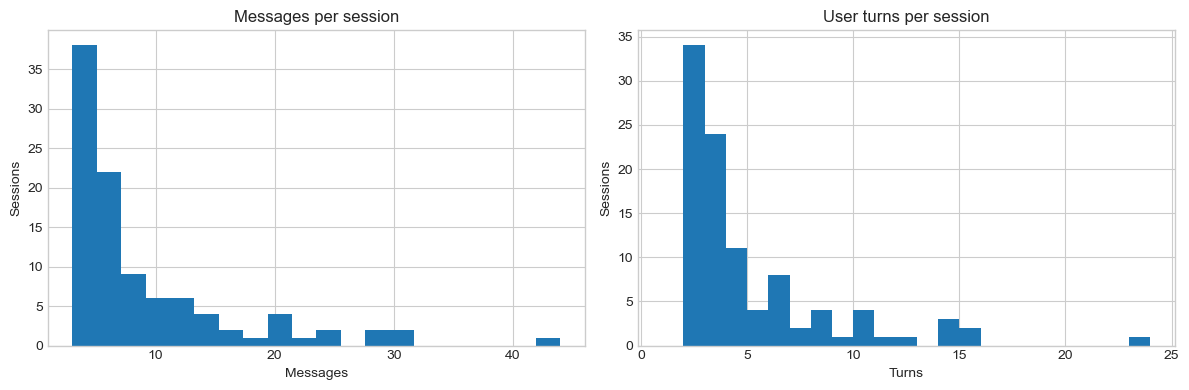

,category,message_count,user_turns,bot_turns,duration_seconds,model_count,provider_count
45,general_athena,44,23,21,173321.0,0,0
40,general_athena,30,15,15,1753.0,1,1
95,other_other,30,15,15,7853.0,1,1
28,general_athena,28,14,14,674.0,1,1
91,other_other,28,14,14,165205.0,1,1


In [7]:
session_metrics = [
    "message_count",
    "user_turns",
    "bot_turns",
    "unanswered_user_turns",
    "user_chars",
    "bot_chars",
    "user_approx_tokens",
    "duration_seconds",
    "model_count",
    "provider_count",
    "model_switch_count",
    "provider_switch_count",
]
session_stats = numeric_summary(sessions, session_metrics)
session_stats.to_csv(TAB / "session_numeric_summary.csv", index=False)
patterns = pd.DataFrame(
    {
        "pattern": [
            "one user turn",
            "multiple user turns",
            "retrieval metadata",
            "attachment",
            "input-config proxy",
            "multiple models",
            "multiple providers",
        ],
        "sessions": [
            sessions.user_turns.eq(1).sum(),
            sessions.user_turns.gt(1).sum(),
            sessions.has_retrieval.sum(),
            sessions.has_attachment.sum(),
            sessions.has_input_config_proxy.sum(),
            sessions.model_count.gt(1).sum(),
            sessions.provider_count.gt(1).sum(),
        ],
    }
)
patterns["percent"] = patterns.sessions / len(sessions) * 100
patterns.to_csv(TAB / "session_pattern_counts.csv", index=False)
display(session_stats.round(2))
display(patterns.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(sessions.message_count, bins=20)
ax[0].set(title="Messages per session", xlabel="Messages", ylabel="Sessions")
ax[1].hist(sessions.user_turns, bins=range(1, int(sessions.user_turns.max()) + 2))
ax[1].set(title="User turns per session", xlabel="Turns", ylabel="Sessions")
fig.tight_layout()
fig.savefig(FIG / "session_depth.png", dpi=160, bbox_inches="tight")
plt.show()
display(
    sessions.nlargest(5, "message_count")[
        [
            "category",
            "message_count",
            "user_turns",
            "bot_turns",
            "duration_seconds",
            "model_count",
            "provider_count",
        ]
    ]
)

**Interpretation.** Multi-turn sessions imply prior-context dependence; message-only cache matching can miss that. These aggregates do not measure cost or usefulness.


## 7. Language analysis

A simple script heuristic counts Persian/Arabic Unicode-block characters and Latin letters. It distinguishes Persian-script, English/Latin-script, mixed Persian/English, mixed/other, and unknown. It is not ground truth: Persian and Arabic share ranges and transliteration is missed.


,language,count,percent
0,Persian-script,422,90.8
1,English/Latin-script,28,6.0
2,mixed Persian/English,13,2.8
3,other/unknown,2,0.4


,language,messages,median_chars,p90_chars
0,English/Latin-script,28,365.5,2537.3
1,Persian-script,422,27.0,134.8
2,mixed Persian/English,13,95.0,1522.2
3,other/unknown,2,2.0,2.0


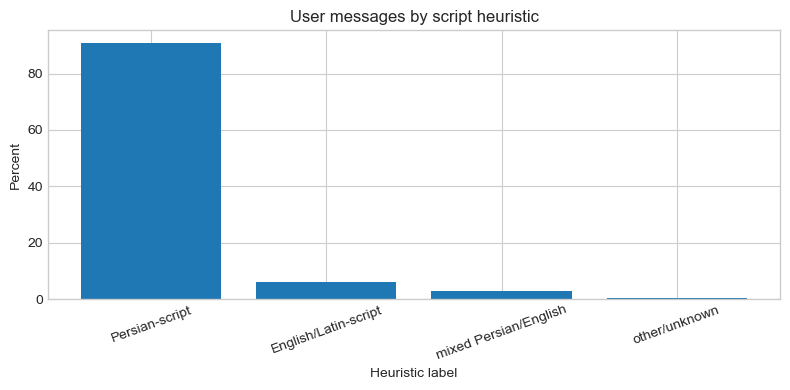

Language by session length and optional features (small cells flagged by counts):


,dominant_user_language,sessions,median_user_turns,median_message_count,median_user_chars,retrieval_sessions,attachment_sessions,input_proxy_sessions,retrieval_session_pct
0,English/Latin-script,10,2.0,4.0,2547.5,2,1,0,20.0
1,Persian-script,88,3.0,6.0,127.0,22,4,8,25.0
2,mixed Persian/English,2,2.5,5.0,3183.0,0,0,0,0.0


In [8]:
language = summarize_values(user, "language")
language.to_csv(TAB / "language_distribution.csv", index=False)
lang_length = (
    user.groupby("language")
    .agg(
        messages=("message_id", "count"),
        median_chars=("char_count", "median"),
        p90_chars=("char_count", percentile_90),
    )
    .reset_index()
)
lang_length.to_csv(TAB / "language_by_length.csv", index=False)
display(language.round(1))
display(lang_length.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(language.language, language.percent)
ax.set(
    title="User messages by script heuristic",
    ylabel="Percent",
    xlabel="Heuristic label",
)
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIG / "language_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

user_lang_session = user.groupby("session_id").language.agg(most_common_value)
user_lang_session = user_lang_session.rename("dominant_user_language").reset_index()
lang_session = sessions.merge(user_lang_session, on="session_id", how="left")
lang_session = (
    lang_session.groupby("dominant_user_language")
    .agg(
        sessions=("session_id", "count"),
        median_user_turns=("user_turns", "median"),
        median_message_count=("message_count", "median"),
        median_user_chars=("user_chars", "median"),
        retrieval_sessions=("has_retrieval", "sum"),
        attachment_sessions=("has_attachment", "sum"),
        input_proxy_sessions=("has_input_config_proxy", "sum"),
    )
    .reset_index()
)
lang_session["retrieval_session_pct"] = (
    100 * lang_session.retrieval_sessions / lang_session.sessions
)
lang_session.to_csv(TAB / "language_by_session_features.csv", index=False)
print(
    "Language by session length and optional features (small cells flagged by counts):"
)
display(lang_session.round(1))

**Interpretation.** Language segments are candidates for tokenizer, quality, and routing evaluation—not evidence about relative model performance.


## 8. Request type and complexity proxies

Keyword flags are nonexclusive and may miss paraphrases. Complexity score adds one point each for ≥500 characters, ≥3 sentence-punctuation marks, code-like patterns, and ≥2 instruction markers. Bands are exploratory—not ground truth or a production classifier.


,heuristic,messages,percent_users
0,heuristic_coding,15,3.225806
1,heuristic_math,1,0.215054
2,heuristic_translation,11,2.365591
3,heuristic_rewrite_edit,7,1.505376
4,heuristic_summarization,2,0.430108
5,heuristic_structured_output,10,2.150538
6,heuristic_long_form_generation,0,0.000000


,complexity_band,messages,median_chars,p90_chars
0,high (3+),7,1949.0,4321.2
1,low (0-1),446,27.0,141.5
2,medium (2),12,1430.0,4132.5


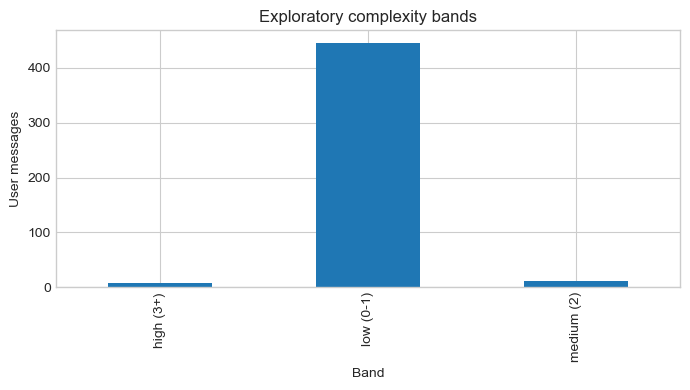

In [9]:
requests = analyze_request_heuristics(messages)
heuristic_columns = [column for column in requests if column.startswith("heuristic_")]
request_types = pd.DataFrame(
    {
        "heuristic": heuristic_columns,
        "messages": [int(requests[column].sum()) for column in heuristic_columns],
    }
)
request_types["percent_users"] = 100 * request_types.messages / len(user)
complexity = (
    requests.loc[requests.role.eq("user")]
    .groupby("complexity_band", dropna=False)
    .agg(
        messages=("message_id", "count"),
        median_chars=("char_count", "median"),
        p90_chars=("char_count", percentile_90),
    )
    .reset_index()
)
request_types.to_csv(TAB / "exploratory_request_heuristics.csv", index=False)
complexity.to_csv(TAB / "exploratory_complexity_bands.csv", index=False)
display(request_types)
display(complexity.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
complexity.dropna(subset=["complexity_band"]).plot(
    kind="bar", x="complexity_band", y="messages", ax=ax, legend=False
)
ax.set(title="Exploratory complexity bands", xlabel="Band", ylabel="User messages")
fig.tight_layout()
fig.savefig(FIG / "complexity_proxy.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation.** Length, code, formatting, language, and session depth provide plausible routing features. They do not prove task difficulty or quality preservation under a cheaper model.


## 9. Model/provider analysis

These are logged bot-message labels, not request cost or quality. Null values and labels like `default`/`workflow` are preserved as observed.


,model,count,percent
0,deepseek-v4-flash,127,28.7
1,gpt-4o-mini,71,16.1
2,gemini-2.5-flash,50,11.3
3,claude-sonnet-4-6,39,8.8
4,default,36,8.1
5,None,27,6.1
6,grok-4-1-fast,21,4.8
7,gemini-2.5-flash-lite,18,4.1
8,gpt-5-nano,15,3.4
9,gpt-4.1-mini,11,2.5


,provider,count,percent
0,deepseek,129,29.2
1,openai_chat_completion,118,26.7
2,google,70,15.8
3,anthropic,39,8.8
4,workflow,36,8.1
5,None,27,6.1
6,grok,21,4.8
7,imagination,2,0.5


,provider,model,bot_messages
3,deepseek,deepseek-v4-flash,127
12,openai_chat_completion,gpt-4o-mini,71
5,google,gemini-2.5-flash,50
0,anthropic,claude-sonnet-4-6,39
17,workflow,default,36
18,NaN,NaN,27
7,grok,grok-4-1-fast,21
6,google,gemini-2.5-flash-lite,18
13,openai_chat_completion,gpt-5-nano,15
10,openai_chat_completion,gpt-4.1-mini,11


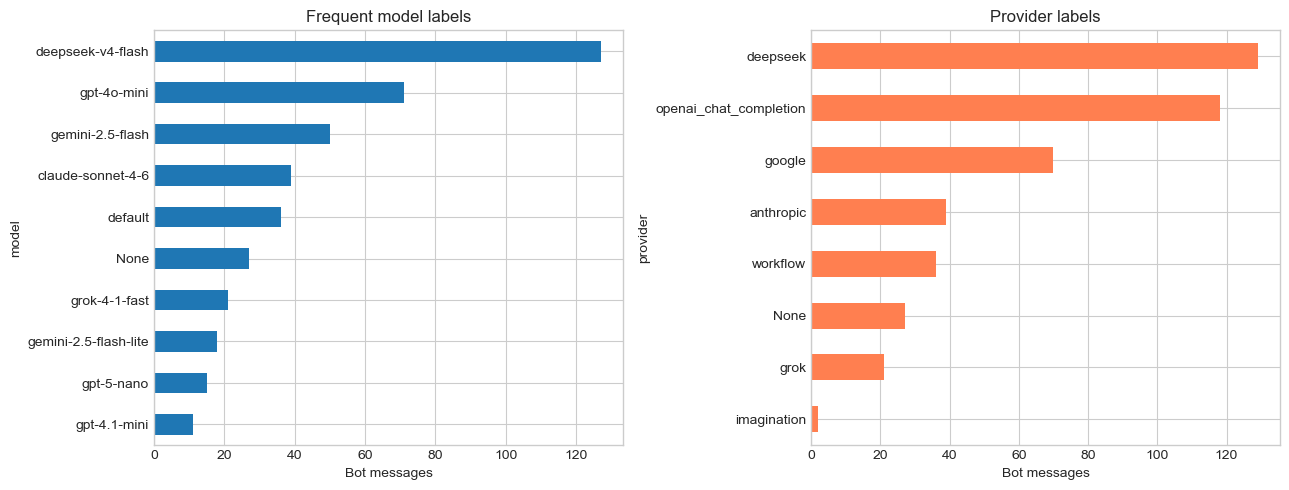

Bot responses without a preceding user request excluded from matched comparison: 6


,model,prompt_bucket,bot_messages,sessions
4,deepseek-v4-flash,short ≤100,107,21
18,gpt-4o-mini,short ≤100,61,15
8,gemini-2.5-flash,short ≤100,39,15
6,default,short ≤100,33,10
0,claude-sonnet-4-6,short ≤100,30,7
5,deepseek-v4-flash,medium 101–500,20,4
25,grok-4-1-fast,short ≤100,19,6
21,gpt-5-nano,short ≤100,15,3
11,gemini-2.5-flash-lite,short ≤100,14,2
1,claude-sonnet-4-6,medium 101–500,9,3


Model assignment by preceding request features (small cells are descriptive):


,feature,model,feature_value,bot_messages,sessions,median_prompt_chars
0,attachment,deepseek-v4-flash,False,127,21,29.0
1,attachment,gpt-4o-mini,False,71,16,28.0
2,attachment,gemini-2.5-flash,False,44,14,47.5
3,code_like,deepseek-v4-flash,False,127,21,29.0
4,code_like,gpt-4o-mini,False,68,15,26.0
5,code_like,gemini-2.5-flash,False,50,15,47.5
6,complexity,deepseek-v4-flash,low (0-1),127,21,29.0
7,complexity,gpt-4o-mini,low (0-1),68,15,26.0
8,complexity,gemini-2.5-flash,low (0-1),47,15,39.0
9,input_config_proxy,deepseek-v4-flash,False,127,21,29.0


In [10]:
model_counts = summarize_values(bot, "model")
provider_counts = summarize_values(bot, "provider")
model_provider_counts = (
    bot.groupby(["provider", "model"], dropna=False)
    .size()
    .rename("bot_messages")
    .reset_index()
    .sort_values("bot_messages", ascending=False)
)
for table_name, table in [
    ("model_distribution", model_counts),
    ("provider_distribution", provider_counts),
    ("model_provider_combinations", model_provider_counts),
]:
    table.to_csv(TAB / f"{table_name}.csv", index=False)
display(model_counts.head(15).round(1))
display(provider_counts.round(1))
display(model_provider_counts.head(15))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
model_counts.head(10).sort_values("count").plot.barh(
    x="model", y="count", ax=axes[0], legend=False
)
axes[0].set(title="Frequent model labels", xlabel="Bot messages")
provider_counts.sort_values("count").plot.barh(
    x="provider", y="count", ax=axes[1], legend=False, color="coral"
)
axes[1].set(title="Provider labels", xlabel="Bot messages")
fig.tight_layout()
fig.savefig(FIG / "model_provider_usage.png", dpi=160, bbox_inches="tight")
plt.show()

# Pair each bot response with the latest preceding user message in message order.
# This preserves model switches instead of assigning one modal model to a session.
requests = analyze_request_heuristics(messages)
paired_responses = pair_bot_responses_with_preceding_users(messages, requests)
session_features = sessions[
    ["session_id", "has_retrieval", "has_attachment", "has_input_config_proxy"]
].rename(columns={"has_attachment": "session_has_attachment"})
paired_responses = paired_responses.merge(session_features, on="session_id", how="left")
unmatched_response_count = int(paired_responses.request_message_id.isna().sum())
paired_responses = paired_responses.loc[
    paired_responses.request_message_id.notna()
].copy()
print(
    f"Bot responses without a preceding user request excluded from matched comparison: {unmatched_response_count}"
)
paired_responses["prompt_bucket"] = pd.cut(
    paired_responses.request_char_count,
    [-1, 100, 500, 10**9],
    labels=["short ≤100", "medium 101–500", "long >500"],
)
model_length = (
    paired_responses.groupby(["model", "prompt_bucket"], observed=True)
    .agg(
        bot_messages=("message_id", "count"),
        sessions=("session_id", "nunique"),
    )
    .reset_index()
)
model_length.to_csv(TAB / "model_by_prompt_length_bucket.csv", index=False)
display(model_length.sort_values("bot_messages", ascending=False).head(18))

paired_responses["request_complexity_band"] = paired_responses.request_message_id.map(
    requests.set_index("message_id").complexity_band
)
feature_columns = {
    "request_language": "language",
    "has_retrieval": "retrieval",
    "session_has_attachment": "attachment",
    "has_input_config_proxy": "input_config_proxy",
    "request_has_code_like_text": "code_like",
    "request_complexity_band": "complexity",
}
feature_summaries = []
for feature, feature_name in feature_columns.items():
    summary = (
        paired_responses.groupby(["model", feature], dropna=False)
        .agg(
            bot_messages=("message_id", "count"),
            sessions=("session_id", "nunique"),
            median_prompt_chars=("request_char_count", "median"),
        )
        .reset_index()
    )
    summary = summary.rename(columns={feature: "feature_value"})
    summary.insert(0, "feature", feature_name)
    feature_summaries.append(summary)
model_feature_table = pd.concat(feature_summaries, ignore_index=True)
model_feature_table.to_csv(TAB / "model_by_request_characteristics.csv", index=False)
print("Model assignment by preceding request features (small cells are descriptive):")
top_model_features = (
    model_feature_table.sort_values(
        ["feature", "bot_messages"], ascending=[True, False]
    )
    .groupby("feature", sort=False)
    .head(3)
)
display(top_model_features.reset_index(drop=True))

**Interpretation.** Heterogeneous assignments make matched comparisons worthwhile. They do not establish waste; intent, workflow constraints, price, and output quality are unavailable.


## 10. Semantic-cache opportunity

Compare exact text, whitespace-only collapse, then conservative Unicode NFKC + casefold + whitespace normalization. Punctuation and wording remain intact. Near-neighbor analysis uses local character n-gram TF-IDF cosine similarity; no paid/external API. Similarity does not establish cache safety.


,normalization,groups,occurrences,percent_user_messages,groups_cross_session
0,literal exact,21,76,16.34,11
1,whitespace collapse,21,76,16.34,11
2,NFKC/casefold/whitespace,21,76,16.34,11


Largest duplicate groups (opaque labels; prompt text omitted):


,duplicate_group,occurrences,distinct_sessions,within_session_repeats,message_ids,median_chars
0,dup_001,26,24,2,ef8f9798c9:0;00c3837851:0;00c3837851:2;672e976...,4.0
1,dup_012,4,1,3,2c932e9ec3:0;2c932e9ec3:8;2c932e9ec3:10;2c932e...,8.0
2,dup_004,4,3,1,f7224e60b5:4;2778422f53:2;28e7ff8db9:5;28e7ff8...,3.0
3,dup_018,3,2,1,9d1ef1d911:2;9d1ef1d911:8;93b6291171:0,6.0
4,dup_016,3,3,0,48b2f4d5f3:2;a0c45cb5d3:10;d88fdd2708:4,5.0
5,dup_011,3,2,1,38419d2e32:2;38419d2e32:4;6a6a6b80c1:6,3.0
6,dup_006,3,2,1,7c4fd612b5:0;00c3837851:7;00c3837851:13,3.0
7,dup_003,3,3,0,f7224e60b5:0;bbe06e1da2:0;1dcc141266:0,13.0


,statistic,value
0,all pairs,107880.000
1,mean,0.017
2,median,0.000
3,p90,0.036
4,p95,0.067
5,p99,0.237
6,max,1.000
7,pairs ≥.70,424.000
8,pairs ≥.85,396.000


,left_message_id,right_message_id,left_session_id_hash,right_session_id_hash,similarity,is_normalized_exact_match,left_chars,right_chars,same_session
0,a1b1737990:2,a1b1737990:4,a1b1737990,a1b1737990,1.0,True,1581,1581,True
1,f7224e60b5:0,1dcc141266:0,f7224e60b5,1dcc141266,1.0,True,13,13,False
2,f7224e60b5:0,bbe06e1da2:0,f7224e60b5,bbe06e1da2,1.0,True,13,13,False
3,bbe06e1da2:0,1dcc141266:0,bbe06e1da2,1dcc141266,1.0,True,13,13,False
4,65f2e7f046:0,0431c8d956:0,65f2e7f046,0431c8d956,1.0,True,4,4,False
5,345224bed0:0,014d15f72d:0,345224bed0,014d15f72d,1.0,True,4,4,False
6,345224bed0:0,07df50229f:0,345224bed0,07df50229f,1.0,True,4,4,False
7,345224bed0:0,3902ccb628:0,345224bed0,3902ccb628,1.0,True,4,4,False
8,345224bed0:0,4683b59e76:0,345224bed0,4683b59e76,1.0,True,4,4,False
9,345224bed0:0,9d1ef1d911:0,345224bed0,9d1ef1d911,1.0,True,4,4,False


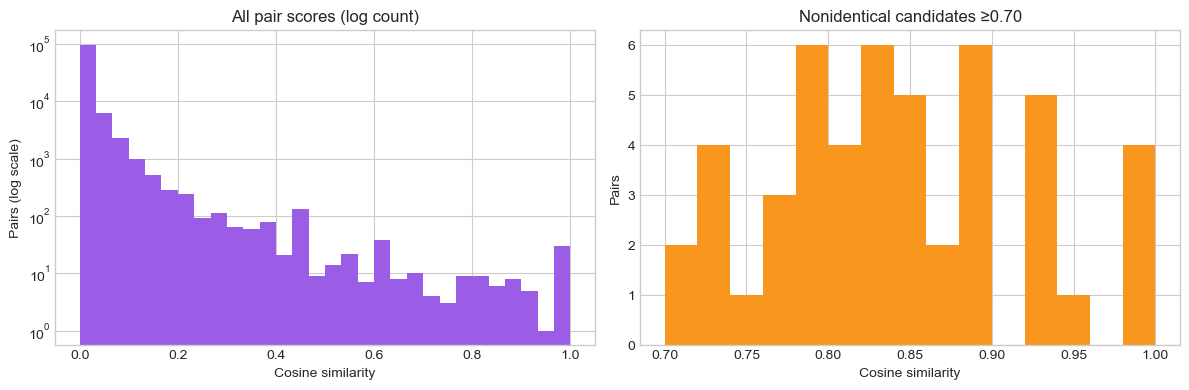

In [11]:
requests["literal"] = requests.content
requests["whitespace_norm"] = requests.content.map(normalize_exact)
requests["safe_norm"] = requests.content.map(normalize_safe)
exact = duplicate_groups(requests, "literal")
whitespace = duplicate_groups(requests, "whitespace_norm")
safe = duplicate_groups(requests, "safe_norm")
for name, table in [
    ("exact_duplicate_groups", exact),
    ("whitespace_duplicate_groups", whitespace),
    ("safe_normalized_duplicate_groups", safe),
]:
    table.to_csv(TAB / f"{name}.csv", index=False)


def repetition_summary(label, duplicate_table):
    occurrences = int(duplicate_table.occurrences.sum()) if len(duplicate_table) else 0
    cross_session_groups = (
        int((duplicate_table.distinct_sessions > 1).sum())
        if len(duplicate_table)
        else 0
    )
    return {
        "normalization": label,
        "groups": len(duplicate_table),
        "occurrences": occurrences,
        "percent_user_messages": 100 * occurrences / len(user),
        "groups_cross_session": cross_session_groups,
    }


repeats = pd.DataFrame(
    [
        repetition_summary("literal exact", exact),
        repetition_summary("whitespace collapse", whitespace),
        repetition_summary("NFKC/casefold/whitespace", safe),
    ]
)
repeats.to_csv(TAB / "exact_repetition_summary.csv", index=False)
display(repeats.round(2))
print("Largest duplicate groups (opaque labels; prompt text omitted):")
display(safe.head(8))

pairs, scores = near_duplicate_pairs(requests, 0.70)
pairs.to_csv(TAB / "near_duplicate_candidates_ge_070.csv", index=False)
if len(scores):
    similarity_summary = pd.DataFrame(
        {
            "statistic": [
                "all pairs",
                "mean",
                "median",
                "p90",
                "p95",
                "p99",
                "max",
                "pairs ≥.70",
                "pairs ≥.85",
            ],
            "value": [
                len(scores),
                np.mean(scores),
                np.median(scores),
                np.quantile(scores, 0.9),
                np.quantile(scores, 0.95),
                np.quantile(scores, 0.99),
                max(scores),
                sum(scores >= 0.7),
                sum(scores >= 0.85),
            ],
        }
    )
else:
    similarity_summary = pd.DataFrame(columns=["statistic", "value"])
similarity_summary.to_csv(TAB / "similarity_distribution_summary.csv", index=False)
display(similarity_summary.round(3))
display(pairs.head(10))

candidate_nonexact = pairs.loc[~pairs.is_normalized_exact_match, "similarity"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(scores, bins=np.linspace(0, 1, 31), color="#9b5de5", log=True)
axes[0].set(
    title="All pair scores (log count)",
    xlabel="Cosine similarity",
    ylabel="Pairs (log scale)",
)
axes[1].hist(candidate_nonexact, bins=np.linspace(0.70, 1, 16), color="#f8961e")
axes[1].set(
    title="Nonidentical candidates ≥0.70", xlabel="Cosine similarity", ylabel="Pairs"
)
fig.tight_layout()
fig.savefig(FIG / "prompt_similarity_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Cache safety.** Even exact text may depend on conversation history, identity, time, or changed retrieval context. Near matches can differ in entity, location, or intent. Candidate pairs are leads only; eligibility needs context scope, invalidation, quality checks, and outcome logs.


## 11. Retrieval/context analysis

For bot messages with `rag`, context strings are joined recursively for character/word and character/4 proxies. Context/query ratio is not full provider-prompt composition. Missing `rag` does not prove retrieval was unused.


RAG records: 71 / 442 bot messages


,metric,count,mean,median,std,min,p25,p50,p75,p90,p95,p99,max
0,context_chars,71,1872.87,1476.00,1290.01,526.0,693.00,1476.00,2899.00,4019.00,4019.00,4019.00,4019.0
1,context_words,71,358.62,282.00,244.79,102.0,128.50,282.00,585.50,766.00,805.00,825.10,830.0
2,context_approx_tokens_char_div4,71,468.51,369.00,322.50,132.0,173.50,369.00,725.00,1005.00,1005.00,1005.00,1005.0
3,rag_query_chars,71,31.20,30.00,11.03,6.0,24.00,30.00,39.50,46.00,49.50,53.90,56.0
4,context_to_query_char_ratio,71,72.68,44.73,85.71,15.7,26.18,44.73,85.87,167.46,178.71,418.52,605.0


,provider,model,messages,median_context_chars,p90_context_chars
0,anthropic,claude-sonnet-4-6,28,626.5,879.8
2,google,gemini-2.5-flash,27,2758.0,4019.0
3,grok,grok-4-1-fast,10,2845.0,4019.0
5,workflow,default,4,1476.0,1716.1
1,deepseek,deepseek-v4-flash,1,798.0,798.0
4,openai_chat_completion,gpt-4.1-nano,1,884.0,884.0


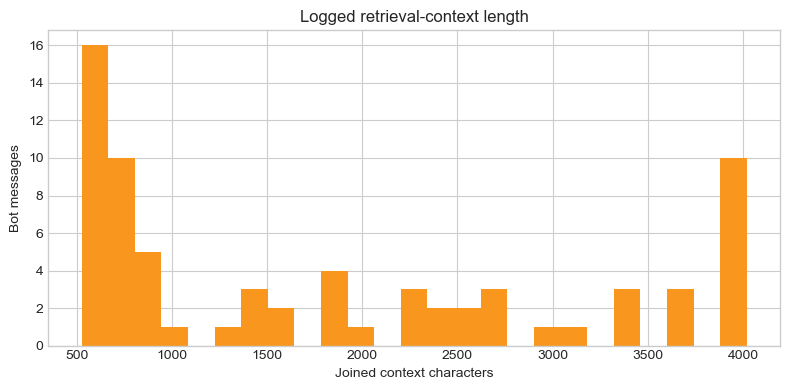

,chars
quantile,
0.50,1476.0
0.90,4019.0
0.95,4019.0
0.99,4019.0
1.00,4019.0


Context by retrieval-query language:


,query_language,retrieval_messages,median_context_chars,p90_context_chars
0,Persian-script,67,1420.0,4019.0
1,mixed Persian/English,4,2746.5,3902.3


Context by session depth:


,depth_band,retrieval_messages,median_context_chars,p90_context_chars
0,≤2 user turns,14,2461.0,4019.0
1,3–5 user turns,29,1970.0,4019.0
2,>5 user turns,28,655.0,3401.0


Context by preceding user complexity proxy:


,preceding_user_complexity,retrieval_messages,median_context_chars,p90_context_chars
0,low (0-1),70,1476.0,4019.0
1,medium (2),1,4019.0,4019.0


In [12]:
context = context_features(messages)
ctx_stats = numeric_summary(
    context,
    [
        "context_chars",
        "context_words",
        "context_approx_tokens_char_div4",
        "rag_query_chars",
        "context_to_query_char_ratio",
    ],
)
ctx_stats.to_csv(TAB / "retrieval_context_numeric_summary.csv", index=False)
ctx_model = (
    context.groupby(["provider", "model"], dropna=False)
    .agg(
        messages=("message_id", "count"),
        median_context_chars=("context_chars", "median"),
        p90_context_chars=("context_chars", percentile_90),
    )
    .reset_index()
    .sort_values("messages", ascending=False)
)
ctx_model.to_csv(TAB / "retrieval_context_by_model_provider.csv", index=False)
print(f"RAG records: {len(context)} / {len(bot)} bot messages")
display(ctx_stats.round(2))
display(ctx_model.head(12).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(context.context_chars, bins=25, color="#f8961e")
ax.set(
    title="Logged retrieval-context length",
    xlabel="Joined context characters",
    ylabel="Bot messages",
)
fig.tight_layout()
fig.savefig(FIG / "retrieval_context_length.png", dpi=160, bbox_inches="tight")
plt.show()
display(
    context.context_chars.quantile([0.5, 0.9, 0.95, 0.99, 1])
    .rename_axis("quantile")
    .to_frame("chars")
)

context["query_language"] = context.rag_query.fillna("").map(detect_language)
context_depth = context.merge(
    sessions[["session_id", "user_turns"]], on="session_id", how="left"
)
context_depth["depth_band"] = pd.cut(
    context_depth.user_turns,
    [-1, 2, 5, 100],
    labels=["≤2 user turns", "3–5 user turns", ">5 user turns"],
)
ctx_lang = (
    context.groupby("query_language")
    .agg(
        retrieval_messages=("message_id", "count"),
        median_context_chars=("context_chars", "median"),
        p90_context_chars=("context_chars", percentile_90),
    )
    .reset_index()
)
ctx_depth_summary = (
    context_depth.groupby("depth_band", observed=True)
    .agg(
        retrieval_messages=("message_id", "count"),
        median_context_chars=("context_chars", "median"),
        p90_context_chars=("context_chars", percentile_90),
    )
    .reset_index()
)
ctx_lang.to_csv(TAB / "retrieval_context_by_query_language.csv", index=False)
ctx_depth_summary.to_csv(TAB / "retrieval_context_by_session_depth.csv", index=False)
print("Context by retrieval-query language:")
display(ctx_lang.round(1))
print("Context by session depth:")
display(ctx_depth_summary.round(1))

# Associate context with the preceding request paired to each bot response.
complexity_by_request = requests.set_index("message_id").complexity_band
context["preceding_user_complexity"] = context.message_id.map(
    paired_responses.set_index("message_id").request_message_id.map(
        complexity_by_request
    )
).fillna("no preceding user message")
ctx_complexity = (
    context.groupby("preceding_user_complexity", dropna=False)
    .agg(
        retrieval_messages=("message_id", "count"),
        median_context_chars=("context_chars", "median"),
        p90_context_chars=("context_chars", percentile_90),
    )
    .reset_index()
)
ctx_complexity.to_csv(
    TAB / "retrieval_context_by_preceding_request_complexity.csv", index=False
)
print("Context by preceding user complexity proxy:")
display(ctx_complexity.round(1))

**Interpretation.** Large/variable context supports testing ranking, deduplication, or trimming. Length alone cannot establish redundancy or safe removability; quality evaluation is required.


## 12. Time analysis

Monthly message/session counts describe observed timestamps only. User-to-next-bot differences are timestamp gaps, not provider/API latency; clock and event semantics are unknown.


,month,sessions
0,2026-01,1
1,2026-03,12
2,2026-04,23
3,2026-05,18
4,2026-06,11
5,2026-07,18
6,2026-08,11
7,2026-09,6


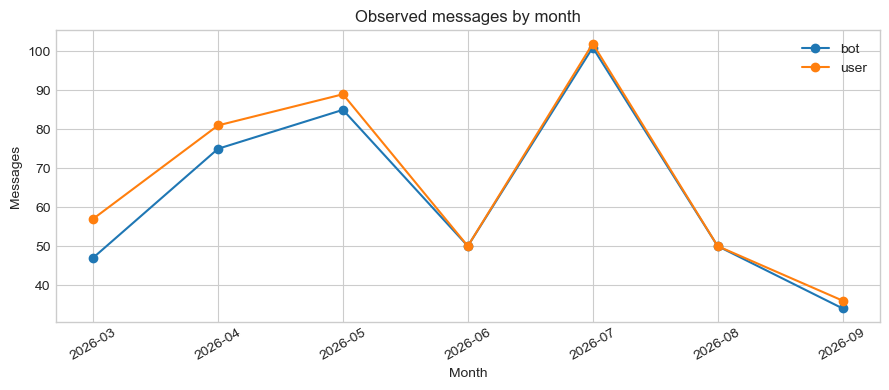

Observed user-to-next-bot timestamp gap: n=99, median=2.0s, p90=7.6s (not API latency)
Sessions where created_at and first-message month differ: 1 of 100
Created-to-first-message gaps >1h: 5 of 100


,check,sessions
0,month differs,1
1,absolute gap >1h,5
2,first message precedes created_at,1


In [13]:
messages["month"] = messages.timestamp_dt.dt.to_period("M").astype(str)
sessions["month"] = sessions.session_created_at.dt.to_period("M").astype(str)
monthly_messages = (
    messages.groupby(["month", "role"]).size().rename("messages").reset_index()
)
monthly_sessions = sessions.groupby("month").size().rename("sessions").reset_index()
monthly_messages.to_csv(TAB / "monthly_messages.csv", index=False)
monthly_sessions.to_csv(TAB / "monthly_sessions.csv", index=False)
display(monthly_sessions)
fig, ax = plt.subplots(figsize=(9, 4))
for role, g in monthly_messages.groupby("role"):
    ax.plot(g.month, g.messages, marker="o", label=role)
ax.set(title="Observed messages by month", xlabel="Month", ylabel="Messages")
ax.tick_params(axis="x", rotation=30)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "traffic_over_time.png", dpi=160, bbox_inches="tight")
plt.show()
gaps = sessions.median_observed_user_to_next_bot_gap_seconds.dropna()
print(
    f"Observed user-to-next-bot timestamp gap: n={len(gaps)}, median={gaps.median():.1f}s, p90={gaps.quantile(.9):.1f}s (not API latency)"
)
# Session created_at vs first observed message timestamp; this detects export date mismatches.
first_times = (
    messages.groupby("session_id")
    .timestamp_dt.min()
    .rename("first_message_time")
    .reset_index()
)
time_audit = sessions[["session_id", "session_created_at"]].merge(
    first_times, on="session_id", how="left"
)
time_audit["created_message_month_match"] = time_audit.session_created_at.dt.to_period(
    "M"
).eq(time_audit.first_message_time.dt.to_period("M"))
time_audit["created_to_first_message_seconds"] = (
    time_audit.first_message_time - time_audit.session_created_at
).dt.total_seconds()
print(
    "Sessions where created_at and first-message month differ:",
    int((~time_audit.created_message_month_match).sum()),
    "of",
    len(time_audit),
)
print(
    "Created-to-first-message gaps >1h:",
    int((time_audit.created_to_first_message_seconds.abs() > 3600).sum()),
    "of",
    len(time_audit),
)
time_audit_summary = pd.DataFrame(
    {
        "check": [
            "month differs",
            "absolute gap >1h",
            "first message precedes created_at",
        ],
        "sessions": [
            int((~time_audit.created_message_month_match).sum()),
            int((time_audit.created_to_first_message_seconds.abs() > 3600).sum()),
            int((time_audit.created_to_first_message_seconds < 0).sum()),
        ],
    }
)
time_audit_summary.to_csv(TAB / "session_timestamp_consistency.csv", index=False)
display(time_audit_summary)

## 13. Segmentation

Compare request length, language, code-like indicators, complexity, and opaque categories. Segment counts are visible so tiny groups are not overread. The features are exploratory candidates, not a production policy.


In [14]:
requests["prompt_bucket"] = pd.cut(
    requests.char_count,
    [-1, 100, 500, 10**9],
    labels=["short ≤100", "medium 101–500", "long >500"],
)
segments = []
for label, column in [
    ("language", "language"),
    ("prompt length", "prompt_bucket"),
    ("code-like", "has_code_like_text"),
    ("complexity", "complexity_band"),
]:
    summary = (
        requests.groupby(column, dropna=False)
        .agg(
            user_messages=("message_id", "count"),
            median_chars=("char_count", "median"),
            p90_chars=("char_count", percentile_90),
        )
        .reset_index()
        .rename(columns={column: "segment"})
    )
    summary.insert(0, "segmentation", label)
    segments.append(summary)
segment_summary = pd.concat(segments, ignore_index=True)
segment_summary.to_csv(TAB / "request_segmentation_summary.csv", index=False)
opaque = (
    sessions.groupby("category")
    .agg(
        sessions=("session_id", "count"),
        median_turns=("user_turns", "median"),
        median_user_chars=("user_chars", "median"),
        retrieval_sessions=("has_retrieval", "sum"),
        attachment_sessions=("has_attachment", "sum"),
        input_proxy_sessions=("has_input_config_proxy", "sum"),
    )
    .reset_index()
)
opaque.to_csv(TAB / "opaque_category_segmentation.csv", index=False)
display(segment_summary.round(1))
display(opaque)
display(
    pd.DataFrame(
        {
            "feature": [
                "length/words",
                "language heuristic",
                "code/format indicators",
                "session depth",
                "RAG/context size",
                "attachments",
                "model/provider",
                "input proxy",
            ],
            "possible use": [
                "request sizing",
                "language-aware evaluation",
                "task/complexity exploration",
                "context dependence",
                "context experiments",
                "multimodal evaluation",
                "baseline assignment",
                "workflow segmentation if verified",
            ],
            "caution": [
                "not exact tokens",
                "not ground truth",
                "heuristics miss intent",
                "timestamps not latency",
                "possibly incomplete logging",
                "payload excluded",
                "no quality/cost",
                "config ≠ usage",
            ],
        }
    )
)

/var/folders/hx/l6n3nlh115n1n5j4480q6pcr0000gn/T/ipykernel_378/1532069284.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  requests.groupby(column, dropna=False)


,segmentation,segment,user_messages,median_chars,p90_chars
0,language,English/Latin-script,42,347.0,4510.2
1,language,Persian-script,800,73.5,499.4
2,language,mixed Persian/English,60,258.5,1581.0
3,language,other/unknown,5,10.0,10.0
4,prompt length,short ≤100,482,28.0,76.0
5,prompt length,medium 101–500,312,204.0,391.9
6,prompt length,long >500,113,1054.0,3281.0
7,code-like,False,871,77.0,561.0
8,code-like,True,36,786.5,5531.5
9,complexity,high (3+),7,1949.0,4321.2


,category,sessions,median_turns,median_user_chars,retrieval_sessions,attachment_sessions,input_proxy_sessions
0,developer_pegahdev,25,3.0,296.0,6,3,0
1,general_athena,25,4.0,149.0,0,2,0
2,operator_gapify,25,3.0,75.0,16,0,7
3,other_other,25,4.0,137.0,2,0,1


,feature,possible use,caution
0,length/words,request sizing,not exact tokens
1,language heuristic,language-aware evaluation,not ground truth
2,code/format indicators,task/complexity exploration,heuristics miss intent
3,session depth,context dependence,timestamps not latency
4,RAG/context size,context experiments,possibly incomplete logging
5,attachments,multimodal evaluation,payload excluded
6,model/provider,baseline assignment,no quality/cost
7,input proxy,workflow segmentation if verified,config ≠ usage


## 14. Business-value analysis

The table separates sample-supported observations from hypotheses and unavailable outcomes. “Directly supported” applies only to the literal usage/count statement—not business impact.


In [ ]:
exact_occ = int(repeats.iloc[0].occurrences)
business = pd.DataFrame(
    [
        {
            "opportunity": "Semantic caching",
            "sample evidence": f"{len(exact)} exact-repeat groups; {exact_occ} user-message occurrences",
            "classification": "Suggestive; validate safety/scale",
            "not shown": "Safe hits, production rate, quality, savings",
        },
        {
            "opportunity": "Intelligent routing",
            "sample evidence": f"Multiple model/provider labels; prompt size {user.char_count.min()}–{user.char_count.max()} chars and varied proxies",
            "classification": "Suggestive; compare matched outcomes",
            "not shown": "Cheaper model preserves quality or improves latency",
        },
        {
            "opportunity": "Context optimization",
            "sample evidence": f"{len(context)} bot messages with RAG; context lengths vary",
            "classification": "Suggestive; test ablations",
            "not shown": "Context can be removed without quality loss",
        },
        {
            "opportunity": "Model/provider selection",
            "sample evidence": f"{bot.model.nunique(dropna=True)} model and {bot.provider.nunique(dropna=True)} provider labels",
            "classification": "Direct: usage heterogeneity only",
            "not shown": "Relative price, capability, or waste",
        },
        {
            "opportunity": "User model-selection burden",
            "sample evidence": "No preference, user-selected model, satisfaction, or abandonment field",
            "classification": "Cannot evaluate",
            "not shown": "Whether users want automation",
        },
        {
            "opportunity": "Cost/quality/true latency",
            "sample evidence": "No verified billing, price, quality, or lifecycle latency fields",
            "classification": "Cannot evaluate",
            "not shown": "Dollar savings, quality preservation, API latency",
        },
        {
            "opportunity": "Observability",
            "sample evidence": "Some model/provider, timestamp, prompt, and optional RAG fields",
            "classification": "Direct: candidate dimensions only",
            "not shown": "Tokens saved, cost avoided, quality maintained",
        },
    ]
)
business.to_csv(TAB / "business_value_assessment.csv", index=False)
display(business)

,opportunity,sample evidence,classification,not shown
0,Semantic caching,21 exact-repeat groups; 76 user-message occurr...,Suggestive; validate safety/scale,"Safe hits, production rate, quality, savings"
1,Intelligent routing,Multiple model/provider labels; prompt size 2–...,Suggestive; compare matched outcomes,Cheaper model preserves quality or improves la...
2,Context optimization,71 bot messages with RAG; context lengths vary,Suggestive; test ablations,Context can be removed without quality loss
3,Model/provider selection,18 model and 7 provider labels,Direct: usage heterogeneity only,"Relative price, capability, or waste"
4,User model-selection burden,"No preference, user-selected model, satisfacti...",Cannot evaluate,Whether users want automation
5,Cost/quality/true latency,"No verified billing, price, quality, or lifecy...",Cannot evaluate,"Dollar savings, quality preservation, API latency"
6,Observability,"Some model/provider, timestamp, prompt, and op...",Direct: candidate dimensions only,"Tokens saved, cost avoided, quality maintained"


### Observability implications

Later customer-facing explanations could show routing features/reason, selected model/provider, exact input/output/billed tokens, cache decision and reason, retrieval changes, request cost, and measured quality/latency. This sample cannot substantiate tokens saved, cost avoided, or maintained quality.


## 15. Limitations

- Only 100 sessions and 907 messages; representativeness is unknown.
- Four equal categories have undocumented meaning and remain opaque.
- Script detection is approximate; transliteration is missed.
- Character/4 is not actual tokenizer output or billing.
- Null and `default`/`workflow` model labels are retained.
- RAG may be incompletely logged; `input` is an uncertain proxy; `instructions` semantics are unverified.
- No exact tokens, price, lifecycle latency, retries/failures, quality, cache outcomes, customer grouping, or user model choice.
- Similarity is not cache safety; long context is not necessarily redundant; associations are not causal.
- Content may include sensitive information; exported evidence excludes raw prompts and URLs.


## 16. Executive findings

The following summary is generated from the analyses above. Interpret each statement as sample-bounded evidence.


In [16]:
findings = [
    f"{len(sessions)} sessions, {len(messages)} messages ({len(user)} user / {len(bot)} bot), four equal opaque strata.",
    f"User request length: median {user.char_count.median():.0f} chars, p90 {user.char_count.quantile(.9):.0f}, range {user.char_count.min()}–{user.char_count.max()}.",
    f'Script heuristic: {(user.language=="Persian-script").sum()} Persian-script and {(user.language=="English/Latin-script").sum()} English/Latin user messages; approximate.',
    f"{bot.model.nunique(dropna=True)} model labels and {bot.provider.nunique(dropna=True)} provider labels: heterogeneity observed, efficiency unknown.",
    f"{len(exact)} exact-repeat groups cover {exact_occ} user-message occurrences; repetition does not equal cache safety.",
    f"RAG metadata appears on {len(context)}/{len(bot)} bot messages; context overhead merits experiments, removability unproven.",
    f"{sessions.user_turns.gt(1).sum()} sessions have multiple user turns; cache/routing must account for context dependence.",
    "Savings, quality preservation, true latency, cache eligibility, and user choice cannot be established from this export.",
]
for i, x in enumerate(findings, 1):
    print(f"{i}. {x}")

1. 100 sessions, 907 messages (465 user / 442 bot), four equal opaque strata.
2. User request length: median 29 chars, p90 182, range 2–4666.
3. Script heuristic: 422 Persian-script and 28 English/Latin user messages; approximate.
4. 18 model labels and 7 provider labels: heterogeneity observed, efficiency unknown.
5. 21 exact-repeat groups cover 76 user-message occurrences; repetition does not equal cache safety.
6. RAG metadata appears on 71/442 bot messages; context overhead merits experiments, removability unproven.
7. 100 sessions have multiple user turns; cache/routing must account for context dependence.
8. Savings, quality preservation, true latency, cache eligibility, and user choice cannot be established from this export.


## 17. Requirements for the full dataset

Prioritize outcomes and linkage: exact input/output/billed tokens; model/version/provider; request and provider cost; lifecycle latency and time-to-first-token; retries/failures; user-selected model and routing decision/reason; cache eligibility/hit/invalidation outcomes; retrieval document IDs/scores and actual prompt composition; quality/evaluation labels; privacy-safe customer/workload grouping. Preserve timezone/clock semantics and stable request/session IDs.


### Reproducibility and source integrity

Important results are visible in this notebook; supporting CSVs/figures live under `reports/sample_eda/`.


In [17]:
raw_hash_after = hashlib.sha256(DATA.read_bytes()).hexdigest()
print("SHA-256 before:", raw_hash_before)
print("SHA-256 after: ", raw_hash_after)
assert raw_hash_before == raw_hash_after, "Raw source changed during analysis"
print(
    "Raw data unchanged. Figures:",
    len(list(FIG.glob("*.png"))),
    "Tables:",
    len(list(TAB.glob("*.csv"))),
)

SHA-256 before: e0f56a2f2340b2ac70bf273e05ee2e9b56126cd3874c0c58659f46b4983549e1
SHA-256 after:  e0f56a2f2340b2ac70bf273e05ee2e9b56126cd3874c0c58659f46b4983549e1
Raw data unchanged. Figures: 8 Tables: 36
